In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

colonnes = ["moteur", "cycle", "reglage_1", "reglage_2", "reglage_3"] + [f"s{i}" for i in range(1, 22)]

train = pd.read_csv("../data/train_FD001.txt", sep=r"\s+", header=None, names=colonnes)
test = pd.read_csv("../data/test_FD001.txt", sep=r"\s+", header=None, names=colonnes)
rul_test = pd.read_csv("../data/RUL_FD001.txt", header=None, names=["RUL"])

print(train.shape, test.shape, rul_test.shape)
train.head()


(20631, 26) (13096, 26) (100, 1)


,moteur,cycle,reglage_1,reglage_2,reglage_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [3]:
# Nombre de cycles maximum de chaque moteur
cycle_max = train.groupby("moteur")["cycle"].max()

# RUL = cycle max du moteur - cycle actuel
train["RUL"] = train["moteur"].map(cycle_max) - train["cycle"]

# Vérification : début et fin du moteur n°1
print(train[train["moteur"] == 1][["moteur", "cycle", "RUL"]].head(3))
print(train[train["moteur"] == 1][["moteur", "cycle", "RUL"]].tail(3))

   moteur  cycle  RUL
0       1      1  191
1       1      2  190
2       1      3  189
     moteur  cycle  RUL
189       1    190    2
190       1    191    1
191       1    192    0


In [4]:
#Cellule 1 : trouver les colonnes constantes
cols_capteurs = [f"s{i}" for i in range(1, 22)]

# Écart-type de chaque réglage et capteur
ecarts = train[["reglage_1", "reglage_2", "reglage_3"] + cols_capteurs].std()

# Une colonne dont l'écart-type est quasi nul ne varie jamais
constantes = ecarts[ecarts < 1e-6].index.tolist()
print("Colonnes constantes :", constantes)

Colonnes constantes : ['reglage_3', 's1', 's5', 's10', 's16', 's18', 's19']


In [5]:
#Cellule 2 : garder les capteurs utiles
colonnes_utiles = [c for c in cols_capteurs if c not in constantes]
print(len(colonnes_utiles), "capteurs utiles :", colonnes_utiles)

15 capteurs utiles : ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


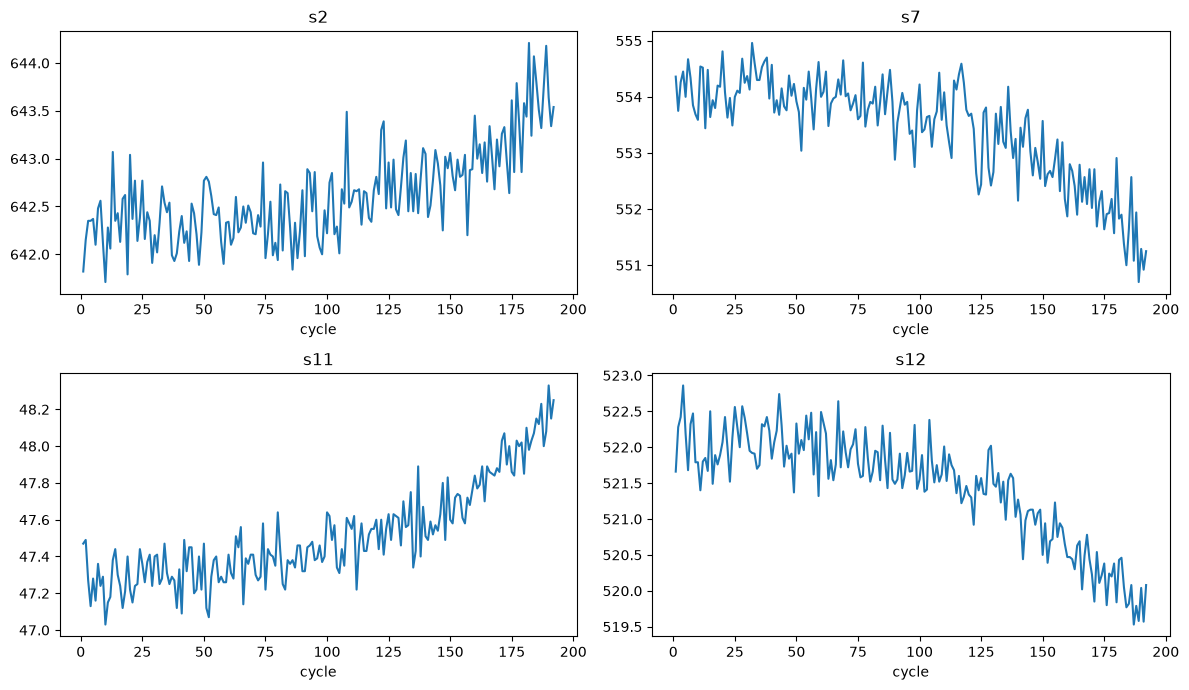

In [6]:
#Cellule 3 : tracer 4 capteurs pour le moteur n°1
moteur_1 = train[train["moteur"] == 1]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, capteur in zip(axes.flat, ["s2", "s7", "s11", "s12"]):
    ax.plot(moteur_1["cycle"], moteur_1[capteur])
    ax.set_title(capteur)
    ax.set_xlabel("cycle")
plt.tight_layout()
plt.show()

## Conclusions de la semaine 1 (Etape 1)

- Jeu de données : NASA C-MAPSS FD001, 100 moteurs en entraînement, 100 en test.
- RUL (durée de vie restante) calculée pour l'entraînement : cycle maximum du moteur moins cycle actuel.
- 7 colonnes constantes écartées (reglage_3, s1, s5, s10, s16, s18, s19). Il reste 15 capteurs utiles.
- Plusieurs capteurs (s2, s7, s11, s12) montrent une tendance nette vers la fin de vie, avec beaucoup de bruit.

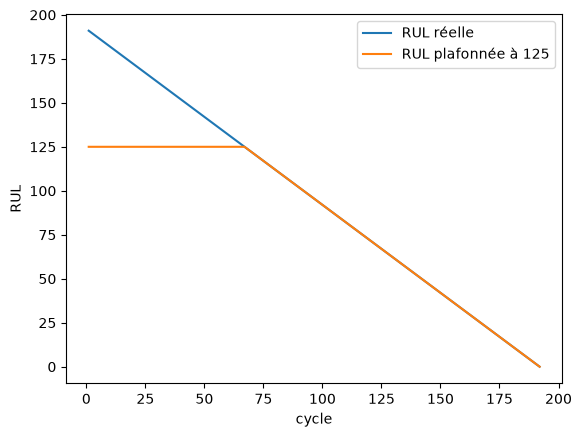

In [10]:
#Étape 1 : plafonner la RUL à 125
#Pourquoi : au début de sa vie, un moteur ne montre aucun signe d’usure. Les capteurs ne peuvent donc pas distinguer 190 cycles restants de 150. Le plafond à 125 concentre le modèle sur la phase où la dégradation est visible.
train["RUL_cap"] = train["RUL"].clip(upper=125)

m1 = train[train["moteur"] == 1]
plt.plot(m1["cycle"], m1["RUL"], label="RUL réelle")
plt.plot(m1["cycle"], m1["RUL_cap"], label="RUL plafonnée à 125")
plt.xlabel("cycle")
plt.ylabel("RUL")
plt.legend()
plt.show()

In [11]:
#Étape 2 : créer les features glissantes
#Pourquoi : les capteurs sont très bruités (vos courbes). La moyenne et l’écart-type sur les 5 derniers cycles, calculés moteur par moteur, lissent le bruit et font ressortir la tendance.
def ajouter_features(df, capteurs, fenetre=5):
    df = df.sort_values(["moteur", "cycle"]).copy()
    groupes = df.groupby("moteur")[capteurs]
    moy = groupes.rolling(fenetre, min_periods=1).mean().reset_index(level=0, drop=True)
    ecart = groupes.rolling(fenetre, min_periods=1).std().reset_index(level=0, drop=True).fillna(0)
    moy.columns = [f"{c}_moy" for c in capteurs]
    ecart.columns = [f"{c}_std" for c in capteurs]
    return pd.concat([df, moy, ecart], axis=1)

train_f = ajouter_features(train, colonnes_utiles)

features = (
    colonnes_utiles
    + [f"{c}_moy" for c in colonnes_utiles]
    + [f"{c}_std" for c in colonnes_utiles]
)
print(len(features), "features")
train_f[features].head()

45 features


,s2,s3,s4,s6,s7,s8,s9,s11,s12,s13,...,s8_std,s9_std,s11_std,s12_std,s13_std,s14_std,s15_std,s17_std,s20_std,s21_std
0,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,...,0.014142,1.499066,0.014142,0.438406,0.035355,5.041671,0.008697,0.000000,0.042426,0.003253
2,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,...,0.020000,4.632023,0.121655,0.404475,0.026458,3.717450,0.007640,1.154701,0.055076,0.044573
3,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,...,0.029861,3.881555,0.171659,0.495950,0.029439,3.050906,0.028117,1.000000,0.076322,0.037977
4,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,...,0.026458,4.587366,0.151063,0.432574,0.025884,2.651326,0.025953,1.095445,0.073621,0.033498


In [12]:
#Étape 3 : séparer entraînement et validation par moteur
#Pourquoi : les cycles d’un même moteur se ressemblent. Si un même moteur se retrouve des deux côtés, le modèle triche et les scores sont faussement bons. On garde donc des moteurs entiers de côté : 80 pour apprendre, 20 pour tester.
from sklearn.model_selection import GroupShuffleSplit

X = train_f[features]
y = train_f["RUL_cap"]
groupes = train_f["moteur"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_val = next(gss.split(X, y, groups=groupes))

X_train, X_val = X.iloc[idx_train], X.iloc[idx_val]
y_train, y_val = y.iloc[idx_train], y.iloc[idx_val]

print("Entraînement :", X_train.shape, "-", groupes.iloc[idx_train].nunique(), "moteurs")
print("Validation   :", X_val.shape, "-", groupes.iloc[idx_val].nunique(), "moteurs")

Entraînement : (16561, 45) - 80 moteurs
Validation   : (4070, 45) - 20 moteurs


Étape 4 : entraîner les trois modèles

Ce qu’on fait : on entraîne trois modèles sur les 80 moteurs d’entraînement, puis on mesure leur erreur sur les 20 moteurs qu’ils n’ont jamais vus.

Régression linéaire : le modèle simple, qui sert de référence.
Random Forest : beaucoup d’arbres de décision dont on fait la moyenne.
Gradient Boosting : des arbres construits les uns après les autres, chacun corrigeant les erreurs du précédent.

Les deux scores :

RMSE : l’erreur moyenne en cycles, qui pénalise davantage les grosses erreurs.
MAE : l’erreur moyenne en cycles, sans pénalité supplémentaire.

Dans les deux cas, plus c’est bas, mieux c’est.

In [13]:
#Cellule 1 : imports et fonction d’évaluation
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluer(modele, nom):
    modele.fit(X_train, y_train)
    pred = modele.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    mae = mean_absolute_error(y_val, pred)
    print(f"{nom} : RMSE = {rmse:.2f} | MAE = {mae:.2f}")
    return {"modèle": nom, "RMSE": round(rmse, 2), "MAE": round(mae, 2)}

In [14]:
#Cellule 2 : entraîner et comparer
resultats = []
resultats.append(evaluer(LinearRegression(), "Régression linéaire"))
resultats.append(evaluer(RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42), "Random Forest"))
resultats.append(evaluer(GradientBoostingRegressor(random_state=42), "Gradient Boosting"))

pd.DataFrame(resultats)

Régression linéaire : RMSE = 19.84 | MAE = 15.91
Random Forest : RMSE = 16.67 | MAE = 11.79
Gradient Boosting : RMSE = 16.42 | MAE = 11.89


,modèle,RMSE,MAE
0,Régression linéaire,19.84,15.91
1,Random Forest,16.67,11.79
2,Gradient Boosting,16.42,11.89


## Conclusions de la semaine 2

- RUL plafonnée à 125 cycles : au début de vie, les capteurs ne montrent aucune usure.
- 45 features : 15 capteurs, leurs moyennes mobiles et leurs écarts-types sur 5 cycles, calculés moteur par moteur.
- Séparation entraînement/validation par moteur (80/20), pour éviter la fuite de données.
- Résultats en validation (RMSE / MAE, en cycles) :
  - Régression linéaire : 19,84 / 15,91
  - Random Forest : 16,67 / 11,79
  - Gradient Boosting : 16,42 / 11,89
- Les deux modèles à base d'arbres battent nettement la régression linéaire. L'écart entre eux est négligeable.